In [32]:
class LR:
    
    def __init__(self):
        self.m = None
        self.b = None

    def fit(self,x_train,y_train):
        num = 0
        den = 0

        x_mean = x_train.mean()
        y_mean = y_train.mean()
        
        for i in range(x_train.shape[0]):
            num = num + ((x_train[i] - x_mean) * (y_train[i]-y_mean))
            den = den + (x_train[i] - x_mean) * (x_train[i] - x_mean)

        self.m = num/den

        self.b = y_train.mean() - (self.m * x_train.mean())

        print(self.m , self.b)

    def predict(self,x_test):
        return self.m * x_test + self.b


In [3]:
import numpy as np
import pandas as pd

In [4]:
df = pd.read_csv(
    "flights.csv",
    usecols=["DISTANCE", "AIR_TIME"]
)

df = df.dropna()

In [12]:
x = df["DISTANCE"].to_numpy()
y = df["AIR_TIME"].to_numpy()

In [13]:
x

array([1448, 2330, 2296, ..., 1598, 1189, 1576], shape=(5714008,))

In [14]:
y

array([169., 263., 266., ..., 197., 144., 189.], shape=(5714008,))

In [16]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=2)

In [17]:
x_train.shape

(4571206,)

In [38]:
lr = LR()

In [39]:
lr.fit(x_train,y_train)

0.11697466313298494 17.075036555396792


In [44]:
y_pred = lr.predict(x_test)

In [34]:
import matplotlib.pyplot as plt

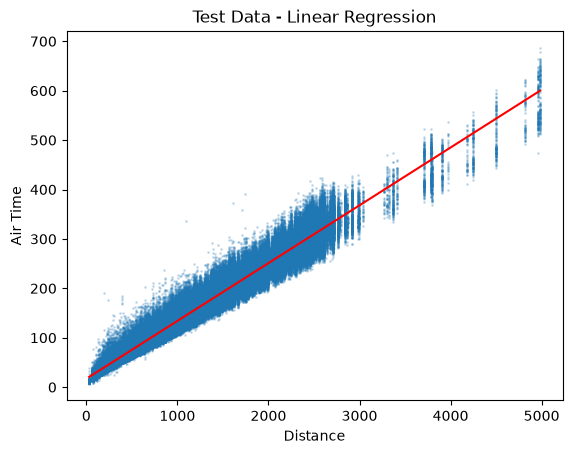

In [43]:
plt.scatter(x_test, y_test, s=1, alpha=0.2)

plt.plot(
    [x_test.min(), x_test.max()],
    [lr.m * x_test.min() + lr.b, lr.m * x_test.max() + lr.b],
    color="red"
)
plt.xlabel("Distance")
plt.ylabel("Air Time")
plt.title("Test Data - Linear Regression")
plt.show()
plt.show()

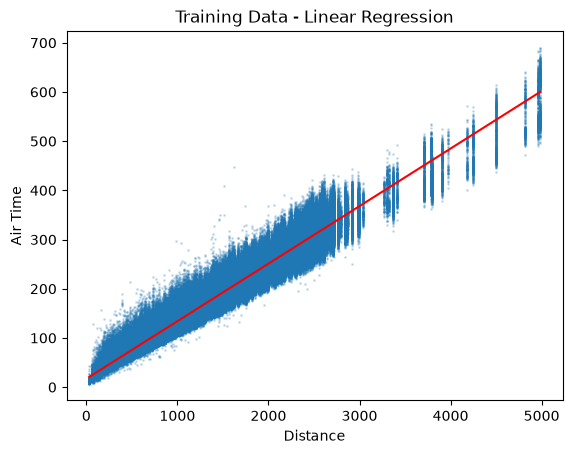

In [42]:
plt.scatter(x_train, y_train, s=1, alpha=0.2)

plt.plot(
    [x_train.min(), x_train.max()],
    [lr.m * x_train.min() + lr.b, lr.m * x_train.max() + lr.b],
    color="red"
)

plt.xlabel("Distance")
plt.ylabel("Air Time")
plt.title("Training Data - Linear Regression")
plt.show()

In [45]:
mae = np.mean(np.abs(y_test - y_pred))
mse = np.mean((y_test - y_pred) ** 2)
rmse = np.sqrt(mse)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

MAE: 8.468169597387119
MSE: 148.8212258750539
RMSE: 12.199230544384916
